In [1]:
import pandas as pd

# Load CSV
data = pd.read_csv("data/Indoor Air Pollution Data.csv", low_memory=False)
data.describe()

FileNotFoundError: [Errno 2] No such file or directory: 'data/Indoor Air Pollution Data.csv'

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 19 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   NH3          173465 non-null  float64
 1   NO2          173468 non-null  object 
 2   CO           173465 non-null  float64
 3   PM2.5        173465 non-null  float64
 4   Temp         173465 non-null  object 
 5   Pressure     173465 non-null  object 
 6   Humidity     173465 non-null  object 
 7   O3           173465 non-null  object 
 8   Date         173465 non-null  object 
 9   Unnamed: 9   1 non-null       float64
 10  Unnamed: 10  1 non-null       float64
 11  Unnamed: 11  1 non-null       float64
 12  Unnamed: 12  1 non-null       float64
 13  Unnamed: 13  1 non-null       float64
 14  Unnamed: 14  1 non-null       float64
 15  Unnamed: 15  1 non-null       float64
 16  Unnamed: 16  1 non-null       float64
 17  Unnamed: 17  1 non-null       float64
 18  Unnamed: 18  1 non-null 

In [3]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [4]:
data.dropna(inplace=True)
# Remove duplicate rows if any
data = data.drop_duplicates()
# Fix numeric columns with bad characters (like '12.450.73')
for col in data.columns[:-1]:  # skip 'Date' column
    data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
    data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [5]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Temp        3526
Pressure    3525
Humidity    3531
dtype: int64


In [6]:
data = data.set_index('Date')

In [7]:

# Constants
R = 0.08205  # Ideal gas constant in (L·atm)/(mol·K)
MW = {
    'CO': 28.01,    # Carbon Monoxide in ppm
    'NO2': 46.01,   # Nitrogen Dioxide in ppm
    'NH3': 17.03,   # Ammonia in ppm
    'O3': 48.00     # Ozone in ppb
}

# Conversion functions
def ppm_to_ugm3(ppm, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppm * mw * pressure_atm * 1000) / (R * (temp_c + 273.15))

def ppb_to_ugm3(ppb, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppb * mw * pressure_atm) / (R * (temp_c + 273.15))

# Ensure relevant columns are numeric
for col in ['CO', 'NO2', 'NH3', 'O3', 'Temp', 'Pressure']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Apply conversions
data['CO_ugm3'] = ppm_to_ugm3(data['CO'], MW['CO'], data['Temp'], data['Pressure'])
data['NO2_ugm3'] = ppm_to_ugm3(data['NO2'], MW['NO2'], data['Temp'], data['Pressure'])
data['NH3_ugm3'] = ppm_to_ugm3(data['NH3'], MW['NH3'], data['Temp'], data['Pressure'])
data['O3_ugm3'] = ppb_to_ugm3(data['O3'], MW['O3'], data['Temp'], data['Pressure'])


In [8]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Temp        3526
Pressure    3525
Humidity    3531
CO_ugm3     3526
NO2_ugm3    3526
NH3_ugm3    3526
O3_ugm3     3526
dtype: int64


In [9]:
# --- Define EAQI breakpoints for each pollutant (in µg/m³) ---
eaqi_breakpoints = {
    'PM2.5': [
        (0.0, 50.4, 0, 50),
        (50.5, 60.4, 51, 100),
        (60.5, 75.4, 101, 150),
        (75.5, 150.4, 151, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.4, 301, 500)
    ],
    'CO_ugm3': [  # Converted from mg/m³ to µg/m³
        (0.0, 5400.0, 0, 50),
        (5401.0, 10400.0, 51, 100),
        (10401.0, 14400.0, 101, 150),
        (14401.0, 17900.0, 151, 200),
        (17901.0, 35400.0, 201, 300),
        (35401.0, 58400.0, 301, 500)
    ],
    'NO2_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ],
    'O3_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ]
}

# --- Function to calculate sub-index for a given pollutant ---
def calculate_eaqi_sub_index(value, breakpoints):
    for BPLo, BPHi, ILo, IHi in breakpoints:
        if BPLo <= value <= BPHi:
            return round(((IHi - ILo) / (BPHi - BPLo)) * (value - BPLo) + ILo)
    return None

# --- Calculate EAQI sub-indices ---
data['EAQI_PM25'] = data['PM2.5'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['PM2.5']))
data['EAQI_CO'] = data['CO_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['CO_ugm3']))
data['EAQI_NO2'] = data['NO2_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['NO2_ugm3']))
data['EAQI_O3'] = data['O3_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['O3_ugm3']))

# --- Final EAQI is the max sub-index across pollutants ---
data['EAQI_Overall'] = data[['EAQI_PM25', 'EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].max(axis=1)

# --- Classify into EAQI categories ---
def classify_eaqi(index_value):
    if pd.isna(index_value):
        return None
    elif index_value <= 50:
        return "Good"
    elif index_value <= 100:
        return "Moderate"
    elif index_value <= 150:
        return "Unhealthy for sensitive groups"
    elif index_value <= 200:
        return "Unhealthy"
    elif index_value <= 300:
        return "Very unhealthy"
    elif index_value <= 500:
        return "Hazardous"
    else:
        return "Out of Range"

data['EAQI_Category'] = data['EAQI_Overall'].apply(classify_eaqi)


In [10]:
# Count each EAQI category
category_counts = data['EAQI_Category'].value_counts().sort_index()

# Format as a table
print("\n📊 EAQI Category Distribution (based on max pollutant per record):\n")
print("| EAQI Category                     | Count     |")
print("|----------------------------------|-----------|")
for category, count in category_counts.items():
    print(f"| {category:<32} | {count:<9} |")


📊 EAQI Category Distribution (based on max pollutant per record):

| EAQI Category                     | Count     |
|----------------------------------|-----------|
| Good                             | 3561      |
| Hazardous                        | 43        |
| Moderate                         | 151223    |
| Unhealthy                        | 2777      |
| Unhealthy for sensitive groups   | 15720     |
| Very unhealthy                   | 141       |


In [11]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
Temp        3526
Pressure    3525
Humidity    3531
CO_ugm3     3526
NO2_ugm3    3526
NH3_ugm3    3526
O3_ugm3     3526
EAQI_CO     3537
EAQI_NO2    3578
EAQI_O3     3612
dtype: int64


In [12]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

  # Replace with your actual file path

# 2. Identify features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
target = 'EAQI_Category'

# 3. Drop columns not needed for training (like EAQI_CO, EAQI_NO2, EAQI_O3)
drop_cols = ['EAQI_CO', 'EAQI_NO2', 'EAQI_O3']
data.drop(columns=[col for col in drop_cols if col in data.columns], inplace=True)

# 4. Check missing values
print("Missing value count:\n", data[features + [target]].isnull().sum())

# 5. Drop rows where target is missing (classification label must be known)
data = data.dropna(subset=[target])

# 6. Impute missing feature values with mean
imputer = SimpleImputer(strategy='mean')
data[features] = imputer.fit_transform(data[features])



# 8. Check if it worked
print("\n✅ Final check: No missing values?\n", data.isnull().sum().sum() == 0)
print("🟢 Class distribution after cleaning:\n", data[target].value_counts())


Missing value count:
 PM2.5               0
CO_ugm3          3526
NO2_ugm3         3526
NH3_ugm3         3526
O3_ugm3          3526
Temp             3526
Humidity         3531
Pressure         3525
EAQI_Category       0
dtype: int64

✅ Final check: No missing values?
 True
🟢 Class distribution after cleaning:
 EAQI_Category
Moderate                          151223
Unhealthy for sensitive groups     15720
Good                                3561
Unhealthy                           2777
Very unhealthy                       141
Hazardous                             43
Name: count, dtype: int64



🔄 Training & Evaluating: Logistic Regression
💾 Saved model: trained_models_under/Logistic_Regression.pkl

🔄 Training & Evaluating: Ridge Classifier
💾 Saved model: trained_models_under/Ridge_Classifier.pkl

🔄 Training & Evaluating: Linear SVM
💾 Saved model: trained_models_under/Linear_SVM.pkl

🔄 Training & Evaluating: Random Forest
💾 Saved model: trained_models_under/Random_Forest.pkl

🔄 Training & Evaluating: Gradient Boosting
💾 Saved model: trained_models_under/Gradient_Boosting.pkl

🔄 Training & Evaluating: XGBoost
💾 Saved model: trained_models_under/XGBoost.pkl

🔄 Training & Evaluating: KNN
💾 Saved model: trained_models_under/KNN.pkl

🔄 Training & Evaluating: Nearest Centroid
💾 Saved model: trained_models_under/Nearest_Centroid.pkl

🔄 Training & Evaluating: MLP Classifier


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/s

💾 Saved model: trained_models_under/MLP_Classifier.pkl

🔄 Training & Evaluating: Naive Bayes
💾 Saved model: trained_models_under/Naive_Bayes.pkl

🔄 Training & Evaluating: LightGBM
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000518 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 338
[LightGBM] [Info] Number of data points in the train set: 162, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000403 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 335
[LightGBM] [Info] Number of data points in the train set: 162, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warn

...

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000446 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 343
[LightGBM] [Info] Number of data points in the train set: 162, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warn

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000436 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 342
[LightGBM] [Info] Number of data points in the train set: 162, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warn

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000287 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 425
[LightGBM] [Info] Number of data points in the train set: 204, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warn

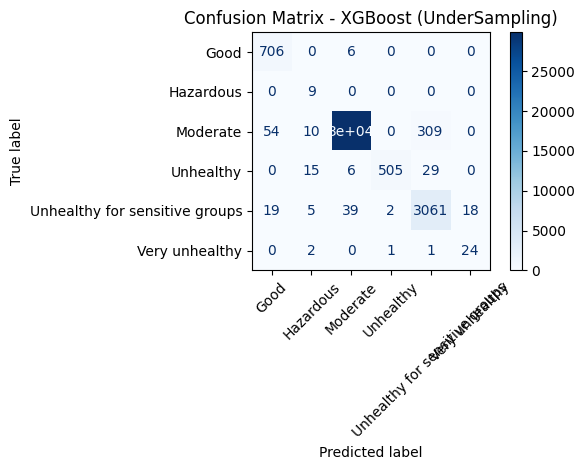

['label_encoder.pkl']

In [14]:
# 1. Import Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
import joblib

# Optional: LightGBM and CatBoost
has_lightgbm = has_catboost = True
try:
    from lightgbm import LGBMClassifier
except ImportError:
    print("⚠️ LightGBM not installed.")
    has_lightgbm = False
try:
    from catboost import CatBoostClassifier
except ImportError:
    print("⚠️ CatBoost not installed.")
    has_catboost = False

# 2. Load and Prepare Data
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Classifiers
model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(max_iter=10000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300),
    "Naive Bayes": GaussianNB()
}
if has_lightgbm:
    model_defs["LightGBM"] = LGBMClassifier(class_weight='balanced', random_state=42)
if has_catboost:
    model_defs["CatBoost"] = CatBoostClassifier(verbose=0, random_state=42)

# 6. Create Pipelines with RandomUnderSampler
models = {}
for name, clf in model_defs.items():
    steps = [('scaler', StandardScaler()), ('undersample', RandomUnderSampler(random_state=42)), ('clf', clf)]
    models[name] = ImbPipeline(steps)

# 7. Train, Evaluate, and Save All Models
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models_under", exist_ok=True)

for name, pipe in models.items():
    print(f"\n🔄 Training & Evaluating: {name}")
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    results[name] = {
        "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
        "CV Macro F1 (std)": round(np.std(f1_scores), 4)
    }
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"trained_models_under/{name.replace(' ', '_')}.pkl")
    print(f"💾 Saved model: trained_models_under/{name.replace(' ', '_')}.pkl")

# 8. Show Summary Table
results_df = pd.DataFrame(results).T.sort_values(by="CV Macro F1 (mean)", ascending=False)
print("\n📊 Model Performance Summary (UnderSampling):")
print(results_df)

# 9. Final Evaluation on Best Model
best_model_name = results_df.index[0]
print(f"\n✅ Final Evaluation on Best Model: {best_model_name}")
best_model = models[best_model_name]
y_pred = best_model.predict(X_test)

print("\n🧾 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Extra metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
mae = mean_absolute_error(y_test, y_pred)

print(f"\n📈 Accuracy: {acc:.4f}")
print(f"📏 Precision (macro): {prec:.4f}")
print(f"📊 Recall (macro): {rec:.4f}")
print(f"⭐ F1-score (macro): {f1:.4f}")
print(f"🧮 MAE: {mae:.4f}")

# 10. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues'
)
plt.title(f"Confusion Matrix - {best_model_name} (UnderSampling)")
plt.tight_layout()
plt.show()

# 11. Save Best Model and Label Encoder
joblib.dump(best_model, "best_model_pipeline_under.pkl")
joblib.dump(le, "label_encoder.pkl")


In [15]:
from imblearn.under_sampling import InstanceHardnessThreshold

models_iht = {}
for name, clf in model_defs.items():
    steps = [
        ('scaler', StandardScaler()),
        ('iht', InstanceHardnessThreshold(estimator=RandomForestClassifier(n_estimators=100, random_state=42))),
        ('clf', clf)
    ]
    models_iht[name] = ImbPipeline(steps)

results_iht = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models_iht", exist_ok=True)

for name, pipe in models_iht.items():
    print(f"\n🔄 [IHT] Training & Evaluating: {name}")
    try:
        f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
        results_iht[name] = {
            "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
            "CV Macro F1 (std)": round(np.std(f1_scores), 4)
        }
        pipe.fit(X_train, y_train)
        joblib.dump(pipe, f"trained_models_iht/{name.replace(' ', '_')}_IHT.pkl")
        print(f"💾 Saved IHT model: trained_models_iht/{name.replace(' ', '_')}_IHT.pkl")
    except Exception as e:
        print(f"❌ Skipped {name} due to error: {e}")



🔄 [IHT] Training & Evaluating: Logistic Regression
💾 Saved IHT model: trained_models_iht/Logistic_Regression_IHT.pkl

🔄 [IHT] Training & Evaluating: Ridge Classifier
💾 Saved IHT model: trained_models_iht/Ridge_Classifier_IHT.pkl

🔄 [IHT] Training & Evaluating: Linear SVM
💾 Saved IHT model: trained_models_iht/Linear_SVM_IHT.pkl

🔄 [IHT] Training & Evaluating: Random Forest
💾 Saved IHT model: trained_models_iht/Random_Forest_IHT.pkl

🔄 [IHT] Training & Evaluating: Gradient Boosting
💾 Saved IHT model: trained_models_iht/Gradient_Boosting_IHT.pkl

🔄 [IHT] Training & Evaluating: XGBoost
💾 Saved IHT model: trained_models_iht/XGBoost_IHT.pkl

🔄 [IHT] Training & Evaluating: KNN
💾 Saved IHT model: trained_models_iht/KNN_IHT.pkl

🔄 [IHT] Training & Evaluating: Nearest Centroid
💾 Saved IHT model: trained_models_iht/Nearest_Centroid_IHT.pkl

🔄 [IHT] Training & Evaluating: MLP Classifier
💾 Saved IHT model: trained_models_iht/MLP_Classifier_IHT.pkl

🔄 [IHT] Training & Evaluating: Naive Bayes
💾 Save

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001910 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1832
[LightGBM] [Info] Number of data points in the train set: 107108, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001745 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1833
[LightGBM] [Info] Number of data points in the train set: 106622, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791760
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001172 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1833
[LightGBM] [Info] Number of data points in the train set: 106830, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001679 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1833
[LightGBM] [Info] Number of data points in the train set: 107091, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.002018 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1833
[LightGBM] [Info] Number of data points in the train set: 134151, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791760
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791760
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No

In [16]:
from imblearn.over_sampling import RandomOverSampler

models_ros = {}
for name, clf in model_defs.items():
    steps = [
        ('scaler', StandardScaler()),
        ('ros', RandomOverSampler(random_state=42)),
        ('clf', clf)
    ]
    models_ros[name] = ImbPipeline(steps)

results_ros = {}
os.makedirs("trained_models_ros", exist_ok=True)

for name, pipe in models_ros.items():
    print(f"\n🔄 [ROS] Training & Evaluating: {name}")
    try:
        f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
        results_ros[name] = {
            "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
            "CV Macro F1 (std)": round(np.std(f1_scores), 4)
        }
        pipe.fit(X_train, y_train)
        joblib.dump(pipe, f"trained_models_ros/{name.replace(' ', '_')}_ROS.pkl")
        print(f"💾 Saved ROS model: trained_models_ros/{name.replace(' ', '_')}_ROS.pkl")
    except Exception as e:
        print(f"❌ Skipped {name} due to error: {e}")



🔄 [ROS] Training & Evaluating: Logistic Regression
💾 Saved ROS model: trained_models_ros/Logistic_Regression_ROS.pkl

🔄 [ROS] Training & Evaluating: Ridge Classifier
💾 Saved ROS model: trained_models_ros/Ridge_Classifier_ROS.pkl

🔄 [ROS] Training & Evaluating: Linear SVM
💾 Saved ROS model: trained_models_ros/Linear_SVM_ROS.pkl

🔄 [ROS] Training & Evaluating: Random Forest
💾 Saved ROS model: trained_models_ros/Random_Forest_ROS.pkl

🔄 [ROS] Training & Evaluating: Gradient Boosting
💾 Saved ROS model: trained_models_ros/Gradient_Boosting_ROS.pkl

🔄 [ROS] Training & Evaluating: XGBoost
💾 Saved ROS model: trained_models_ros/XGBoost_ROS.pkl

🔄 [ROS] Training & Evaluating: KNN
💾 Saved ROS model: trained_models_ros/KNN_ROS.pkl

🔄 [ROS] Training & Evaluating: Nearest Centroid
💾 Saved ROS model: trained_models_ros/Nearest_Centroid_ROS.pkl

🔄 [ROS] Training & Evaluating: MLP Classifier
💾 Saved ROS model: trained_models_ros/MLP_Classifier_ROS.pkl

🔄 [ROS] Training & Evaluating: Naive Bayes
💾 Save

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008716 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1832
[LightGBM] [Info] Number of data points in the train set: 580692, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009857 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1832
[LightGBM] [Info] Number of data points in the train set: 580692, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.008197 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1832
[LightGBM] [Info] Number of data points in the train set: 580698, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.007218 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1832
[LightGBM] [Info] Number of data points in the train set: 580698, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.009499 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1833
[LightGBM] [Info] Number of data points in the train set: 725868, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
💾 Saved ROS model: trained_models_ros/LightGBM_ROS.pkl

🔄 [ROS] Training & Evaluating: CatBoost
💾 